## Q1

[-1  0  1 ... 76 75 76]
[  1   2   1 ... -78 -77 -76]
[-1  0  1 ... 46 47 46]
[ -1  -2  -1 ... -42 -41 -40]
[ -1  -2  -1 ... -32 -31 -30]
[ 1  0  1 ...  0 -1  0]
[ -1   0   1 ... -46 -47 -46]
[  1   0   1 ... -20 -19 -20]
[ 1  0  1 ... 14 15 14]
[-1 -2 -3 ... 46 45 44]
[  1   2   1 ... -12 -11 -10]
[ 1  2  1 ... 18 19 20]
[  1   2   1 ... -16 -15 -14]
[  -1   -2   -3 ... -130 -131 -132]
[ 1  0 -1 ... -2 -1  0]
[-1  0 -1 ...  2  3  2]
[ 1  0  1 ... 34 33 32]
[ 1  2  3 ... 46 47 46]
[-1  0 -1 ...  2  3  2]
[ 1  0  1 ... 58 57 56]
[  1   0   1 ... -14 -15 -14]
[  1   2   1 ... 122 123 124]
[ 1  0 -1 ...  0 -1  0]
[ 1  0 -1 ... 28 27 26]
[-1  0 -1 ... 66 65 66]
[ -1  -2  -3 ... -44 -43 -44]
[   1    0   -1 ... -184 -185 -184]
[ 1  0 -1 ... -6 -5 -4]
[  1   2   3 ... -40 -41 -40]
[  1   2   1 ... -26 -27 -28]
[ 1  2  3 ... 18 19 20]
[-1  0 -1 ... -4 -3 -4]
[  1   2   3 ... -70 -69 -70]
[ -1   0  -1 ... -18 -17 -16]
[  1   0  -1 ... -64 -65 -66]
[  1   2   1 ... -70 -69 -70]
[  1   0  -1 ...

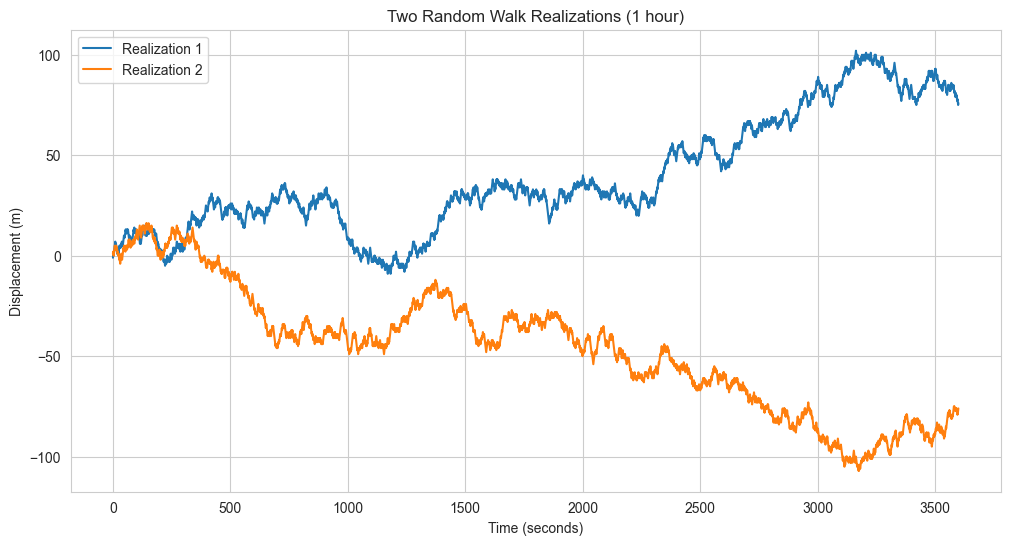

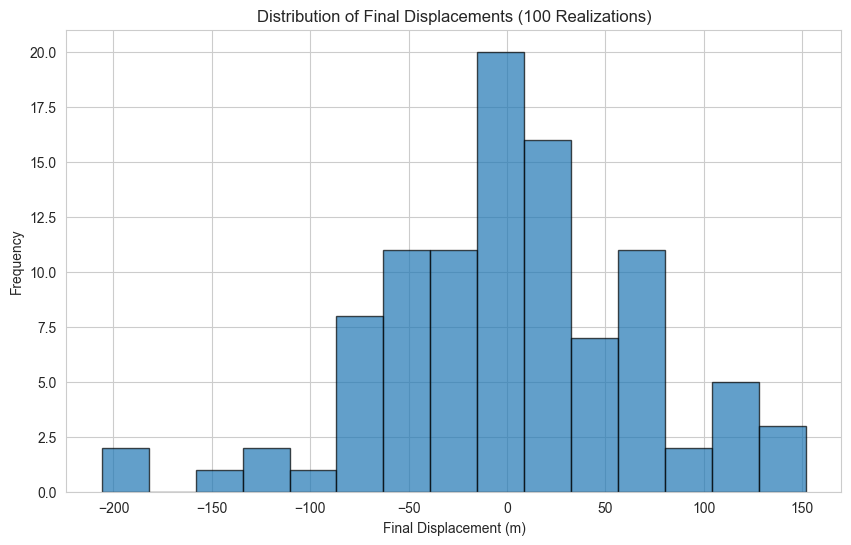

Mean displacement after 1 hour: 2.88 m
RMS displacement after 1 hour: 65.76 m


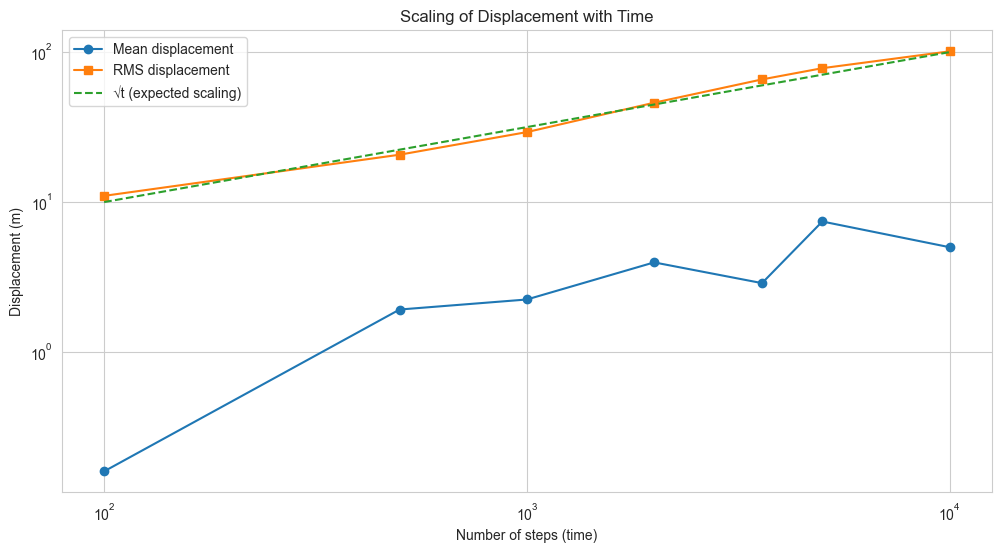

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better looking plots
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Parameters
num_steps = 3600  # 1 hour = 3600 seconds
num_realizations = 100

# Simulate 100 random walks with different seeds
displacements = np.zeros(num_realizations)
all_walks = []

for i in range(num_realizations):
    np.random.seed(i)  # Different seed for each realization
    steps = np.random.choice([-1, 1], size=num_steps)
    walk = np.cumsum(steps)
    all_walks.append(walk)
    displacements[i] = walk[-1]  # Final displacement

# Plot two example walks
plt.figure(figsize=(12, 6))
plt.plot(all_walks[0], label='Realization 1')
plt.plot(all_walks[1], label='Realization 2')
plt.xlabel('Time (seconds)')
plt.ylabel('Displacement (m)')
plt.title('Two Random Walk Realizations (1 hour)')
plt.legend()
plt.show()

# Plot histogram of final displacements
plt.figure(figsize=(10, 6))
plt.hist(displacements, bins=15, edgecolor='black', alpha=0.7)
plt.xlabel('Final Displacement (m)')
plt.ylabel('Frequency')
plt.title('Distribution of Final Displacements (100 Realizations)')
plt.show()

# Calculate mean and RMS displacement
mean_displacement = np.mean(displacements)
rms_displacement = np.sqrt(np.mean(displacements**2))

print(f"Mean displacement after 1 hour: {mean_displacement:.2f} m")
print(f"RMS displacement after 1 hour: {rms_displacement:.2f} m")

# Investigate scaling with time
time_points = [100, 500, 1000, 2000, 3600, 5000, 10000]
mean_disp = []
rms_disp = []

for t in time_points:
    temp_disp = []
    for i in range(num_realizations):
        np.random.seed(i)
        steps = np.random.choice([-1, 1], size=t)
        walk = np.cumsum(steps)
        temp_disp.append(walk[-1])
    mean_disp.append(np.mean(temp_disp))
    rms_disp.append(np.sqrt(np.mean(np.array(temp_disp)**2)))

plt.figure(figsize=(12, 6))
plt.plot(time_points, mean_disp, 'o-', label='Mean displacement')
plt.plot(time_points, rms_disp, 's-', label='RMS displacement')
plt.plot(time_points, np.sqrt(time_points), '--', label='√t (expected scaling)')
plt.xlabel('Number of steps (time)')
plt.ylabel('Displacement (m)')
plt.title('Scaling of Displacement with Time')
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.show()

## Q2

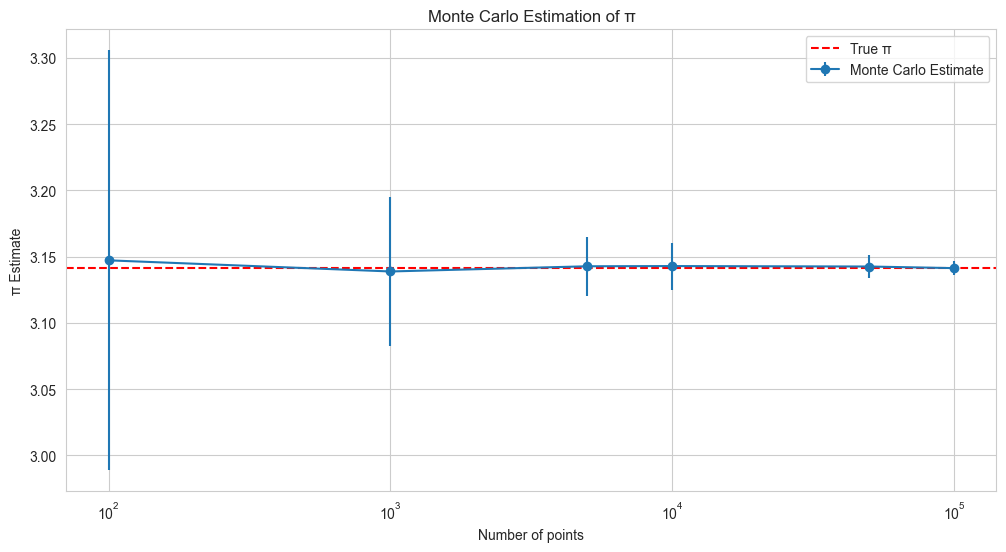

Final estimate with 100000 points: 3.141321 (error: 0.01%)


In [26]:
def estimate_pi(num_points):
    x = np.random.uniform(-1, 1, num_points)
    y = np.random.uniform(-1, 1, num_points)
    inside = (x**2 + y**2) <= 1
    pi_estimate = 4 * np.mean(inside)
    return pi_estimate

# Estimate pi with increasing number of points
num_points_list = [100, 1000, 5000, 10000, 50000, 100000]
pi_estimates = []
std_errors = []

for n in num_points_list:
    estimates = [estimate_pi(n) for _ in range(100)]
    pi_estimates.append(np.mean(estimates))
    std_errors.append(np.std(estimates))

# Plot results
plt.figure(figsize=(12, 6))
plt.errorbar(num_points_list, pi_estimates, yerr=std_errors, fmt='o-', 
             label='Monte Carlo Estimate')
plt.axhline(np.pi, color='r', linestyle='--', label='True π')
plt.xlabel('Number of points')
plt.ylabel('π Estimate')
plt.title('Monte Carlo Estimation of π')
plt.xscale('log')
plt.legend()
plt.show()

print(f"Final estimate with {num_points_list[-1]} points: {pi_estimates[-1]:.6f} (error: {abs(pi_estimates[-1]-np.pi)/np.pi*100:.2f}%)")

## Q3

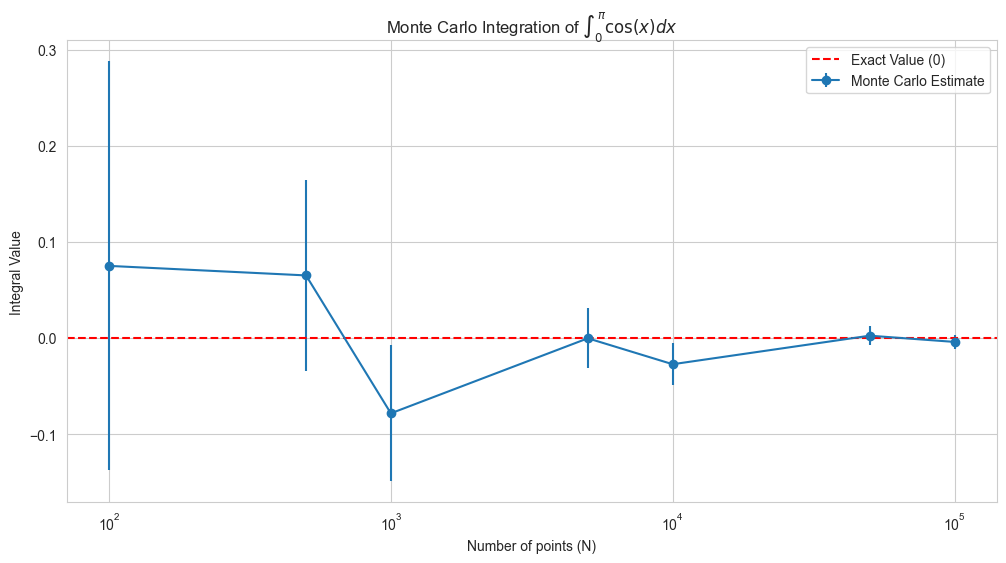

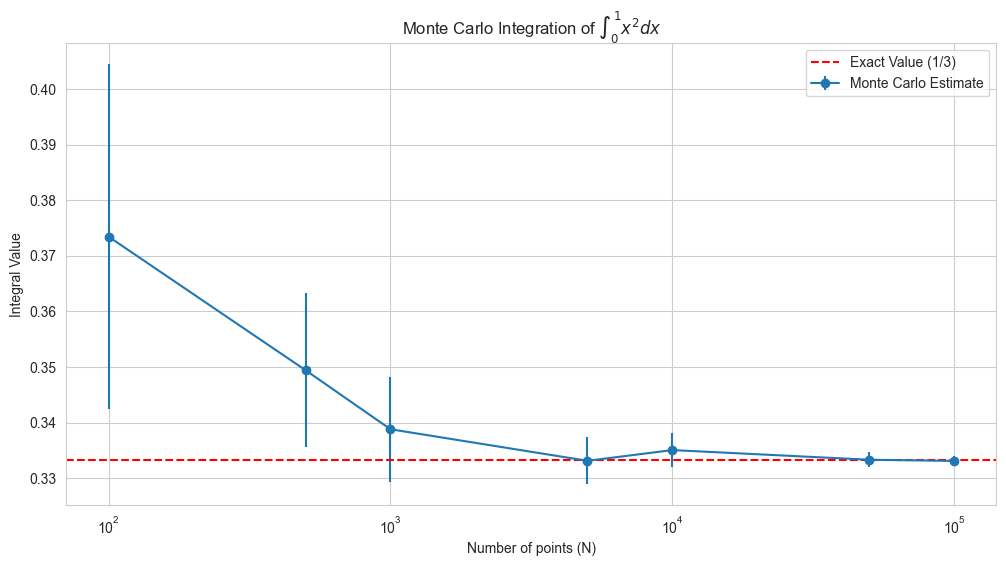

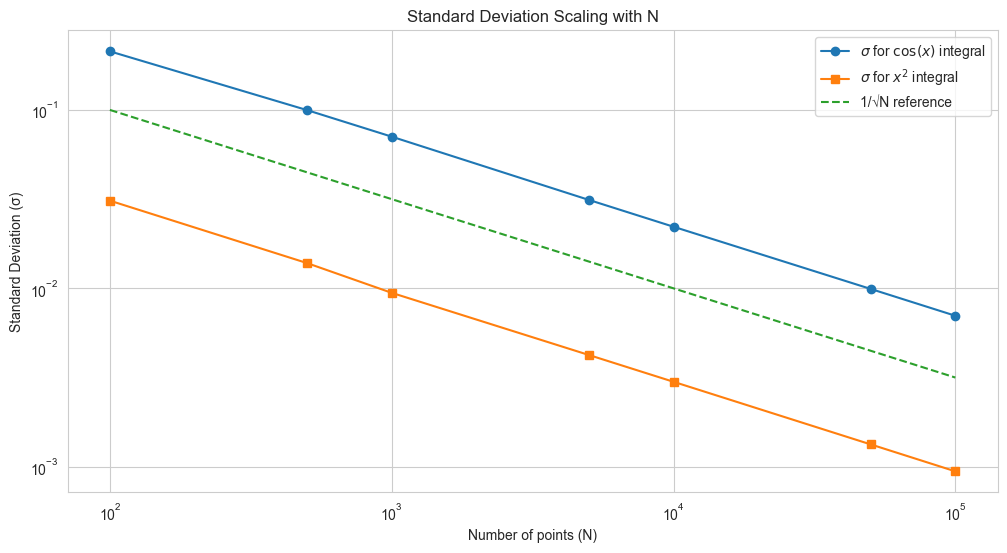

In [27]:
def monte_carlo_integrate(func, a, b, num_points):
    x = np.random.uniform(a, b, num_points)
    integral = (b - a) * np.mean(func(x))
    # Estimate standard deviation
    func_values = func(x)
    std = (b - a) * np.std(func_values) / np.sqrt(num_points)
    return integral, std

# First integral: ∫₀ᵽᴵ cos(x) dx (exact answer: sin(π) - sin(0) = 0)
def func1(x):
    return np.cos(x)

# Second integral: ∫₀¹ x² dx (exact answer: 1/3)
def func2(x):
    return x**2

# Calculate for different N values
N_values = [100, 500, 1000, 5000, 10000, 50000, 100000]
results1 = []
results2 = []
std1 = []
std2 = []

for N in N_values:
    int1, sigma1 = monte_carlo_integrate(func1, 0, np.pi, N)
    int2, sigma2 = monte_carlo_integrate(func2, 0, 1, N)
    results1.append(int1)
    results2.append(int2)
    std1.append(sigma1)
    std2.append(sigma2)

# Plot results for first integral
plt.figure(figsize=(12, 6))
plt.errorbar(N_values, results1, yerr=std1, fmt='o-', label='Monte Carlo Estimate')
plt.axhline(0, color='r', linestyle='--', label='Exact Value (0)')
plt.xlabel('Number of points (N)')
plt.ylabel('Integral Value')
plt.title(r'Monte Carlo Integration of $\int_0^\pi \cos(x) dx$')
plt.xscale('log')
plt.legend()
plt.show()

# Plot results for second integral
plt.figure(figsize=(12, 6))
plt.errorbar(N_values, results2, yerr=std2, fmt='o-', label='Monte Carlo Estimate')
plt.axhline(1/3, color='r', linestyle='--', label='Exact Value (1/3)')
plt.xlabel('Number of points (N)')
plt.ylabel('Integral Value')
plt.title(r'Monte Carlo Integration of $\int_0^1 x^2 dx$')
plt.xscale('log')
plt.legend()
plt.show()

# Plot standard deviation scaling
plt.figure(figsize=(12, 6))
plt.loglog(N_values, std1, 'o-', label=r'$\sigma$ for $\cos(x)$ integral')
plt.loglog(N_values, std2, 's-', label=r'$\sigma$ for $x^2$ integral')
plt.loglog(N_values, 1/np.sqrt(N_values), '--', label='1/√N reference')
plt.xlabel('Number of points (N)')
plt.ylabel('Standard Deviation (σ)')
plt.title('Standard Deviation Scaling with N')
plt.legend()
plt.show()

## Q4

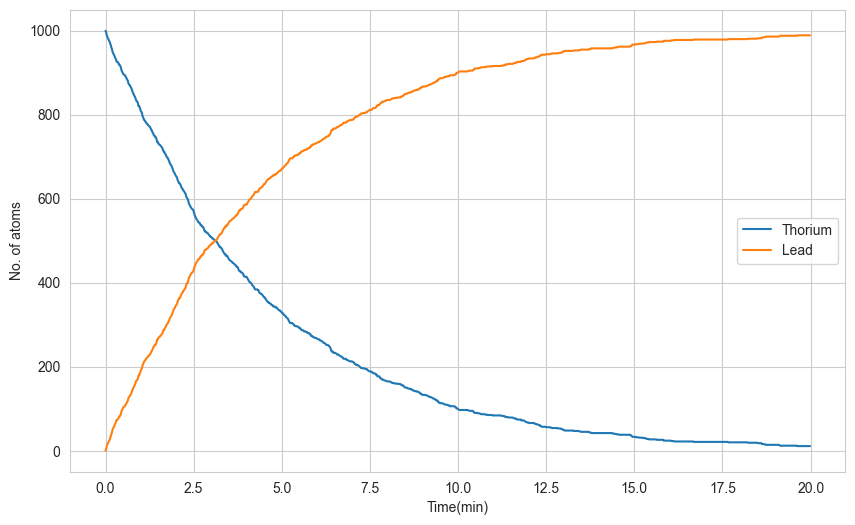

In [4]:
hl=3.053*60
lam=np.log(2)/hl
T=np.arange(0,20*60,1)
prob=(1-np.exp(-lam))
th=1000
pb=0
PB=[pb]
TH=[th]
#print(z)
for i in range(len(T)-1):
    z=np.random.binomial(th,prob)
    th=th-z
    pb=pb+z
    PB.append(pb)
    TH.append(th)
plt.plot(T/60,TH, label='Thorium')
plt.plot(T/60,PB, label = 'Lead')
plt.xlabel('Time(min)')
plt.ylabel('No. of atoms')
plt.legend()
plt.show()